# Shoplifting Detection - video classification

In [49]:
import os, re, glob, zipfile, random, math, copy, warnings
import numpy as np, pandas as pd, cv2
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
warnings.filterwarnings("ignore")

DATA_URL = "https://drive.google.com/file/d/1KCKfyIGbQi8a7bIYta3LM8dFStxVzVX-/view?usp=sharing"          # link to the zip file; leave empty to use a dataset attached to the notebook
WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./work"
os.makedirs(WORK, exist_ok=True)

T, K = 16, 32          # frames per clip fed to the model / frames cached per video
CACHE_SIZE, IMG = 128, 112
BATCH, EPOCHS, LR, WD, PATIENCE = 16, 80, 1e-3, 1e-2, 25
SEED = 42

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = device.type == "cuda"
print(device)

cuda


## Data

In [34]:
VIDEO_EXT = {".mp4", ".avi", ".mov", ".mkv", ".wmv", ".flv", ".webm", ".mpg", ".mpeg"}

def fetch(url, dst):
    if os.path.isdir(dst) and os.listdir(dst):
        return dst
    os.makedirs(dst, exist_ok=True)
    zpath = os.path.join(WORK, "data.zip")
    if "drive.google.com" in url:
        import gdown
        gdown.download(url, zpath, quiet=False, fuzzy=True)
    else:
        import requests
        with requests.get(url, stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(zpath, "wb") as f:
                for chunk in r.iter_content(1 << 20):
                    f.write(chunk)
    with zipfile.ZipFile(zpath) as z:
        z.extractall(dst)
    os.remove(zpath)
    return dst

ROOT = fetch(DATA_URL, os.path.join(WORK, "data")) if DATA_URL else "/kaggle/input"
videos = sorted(p for p in glob.glob(os.path.join(ROOT, "**", "*"), recursive=True)
                if os.path.splitext(p)[1].lower() in VIDEO_EXT)
print(len(videos), "videos")
print(pd.Series([os.path.relpath(os.path.dirname(p), ROOT) for p in videos]).value_counts().head(20))

855 videos
Shop DataSet/non shop lifters    531
Shop DataSet/shop lifters        324
Name: count, dtype: int64


In [35]:
LABEL_MAP = {}   # only if labels are not inferred, e.g. {"class_a": 0, "class_b": 1}
NEG = re.compile(r"non|normal|(?<![a-z])no(?![a-z])|negative|regular|honest|clean|genuine")
POS = re.compile(r"shoplift|theft|steal|stole|thie|robber")
SPLITS = {"train": "train", "training": "train", "val": "val", "valid": "val",
          "validation": "val", "test": "test", "testing": "test"}

def infer(path):
    parts = os.path.relpath(path, ROOT).lower().split(os.sep)
    parts[-1] = os.path.splitext(parts[-1])[0]
    label, split = None, None
    for s in list(reversed(parts[:-1])) + [parts[-1]]:
        if label is None:
            if s in LABEL_MAP: label = LABEL_MAP[s]
            elif NEG.search(s): label = 0
            elif POS.search(re.sub("[^a-z0-9]+", "", s)): label = 1
        if split is None and s in SPLITS: split = SPLITS[s]
    return label, split

df = pd.DataFrame({"path": videos})
df["label"], df["split"] = zip(*df.path.map(infer))
print(df.label.value_counts(dropna=False).to_dict(), df.split.value_counts(dropna=False).to_dict())
df = df.dropna(subset=["label"]).reset_index(drop=True)
df["label"] = df.label.astype(int)
assert df.label.nunique() == 2, "Labels not inferred. Fill LABEL_MAP with the class folder names printed above."

{0: 531, 1: 324} {None: 855}


## Frame sampling

In [36]:
def sample_indices(n, t, jitter=False):
    skip = n / t
    pos = (np.arange(t) + (np.random.rand(t) if jitter else 0.5)) * skip
    return np.clip(pos.astype(int), 0, n - 1)

for n in [1, 5, 16, 17, 31, 100, 299, 1000, 5000]:
    i = sample_indices(n, T)
    assert len(i) == T and i.min() >= 0 and i.max() < n and (np.diff(i) >= 0).all()
    if n >= T:
        assert i[0] < n / T and i[-1] >= n - n / T - 1 and np.ptp(np.diff(i)) <= 1
for n in [20, 100, 450]:
    print(n, sample_indices(n, T).tolist())

20 [0, 1, 3, 4, 5, 6, 8, 9, 10, 11, 13, 14, 15, 16, 18, 19]
100 [3, 9, 15, 21, 28, 34, 40, 46, 53, 59, 65, 71, 78, 84, 90, 96]
450 [14, 42, 70, 98, 126, 154, 182, 210, 239, 267, 295, 323, 351, 379, 407, 435]


## Frame cache and metadata

In [37]:
def extract(path):
    cap = cv2.VideoCapture(path)
    n = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    fps = cap.get(cv2.CAP_PROP_FPS) or np.nan
    w, h = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    if n <= 0:
        n = 0
        while cap.grab(): n += 1
        cap.release(); cap = cv2.VideoCapture(path)
    if n <= 0:
        return None
    need = sample_indices(n, K)
    keep, got, i = set(need.tolist()), {}, 0
    while i <= need.max() and cap.grab():
        if i in keep:
            ok, f = cap.retrieve()
            if ok:
                f = cv2.cvtColor(f, cv2.COLOR_BGR2RGB)
                got[i] = cv2.resize(f, (CACHE_SIZE, CACHE_SIZE), interpolation=cv2.INTER_AREA)
        i += 1
    cap.release()
    if not got:
        return None
    ks = np.array(sorted(got))
    near = ks[np.abs(ks[None] - need[:, None]).argmin(1)]
    return dict(n=n, fps=fps, w=w, h=h), np.stack([got[k] for k in near])

res = Parallel(n_jobs=-1)(delayed(extract)(p) for p in tqdm(df.path))
good = np.array([r is not None for r in res])
print("unreadable videos:", (~good).sum())
df = pd.concat([df[good].reset_index(drop=True), pd.DataFrame([r[0] for r in res if r is not None])], axis=1)
frames = np.stack([r[1] for r in res if r is not None])
del res
df["sec"] = df.n / df.fps
print(frames.shape, frames.nbytes / 1e9, "GB")
labels = df.label.values

  0%|          | 0/855 [00:00<?, ?it/s]

unreadable videos: 0
(855, 32, 128, 128, 3) 1.34479872 GB


## EDA

label
normal         531
shoplifting    324
             n     fps     sec      w      h
count   855.00  855.00  855.00  855.0  855.0
mean    331.42   24.95   13.28  704.0  576.0
std     119.38    0.09    4.78    0.0    0.0
min      75.00   24.75    3.00  704.0  576.0
25%     250.00   25.00   10.02  704.0  576.0
50%     325.00   25.00   13.00  704.0  576.0
75%     396.00   25.00   16.00  704.0  576.0
max    1850.00   25.00   74.00  704.0  576.0


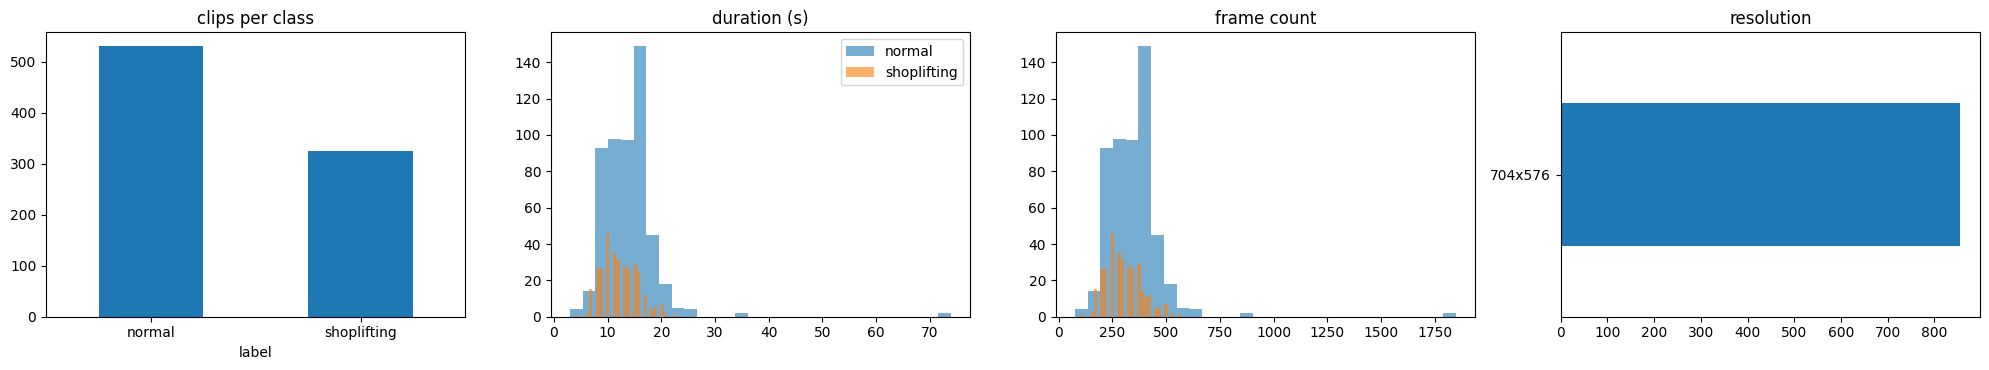

In [38]:
names = {0: "normal", 1: "shoplifting"}
print(df.label.map(names).value_counts().to_string())
print(df[["n", "fps", "sec", "w", "h"]].describe().round(2).to_string())

fig, ax = plt.subplots(1, 4, figsize=(20, 3.8))
df.label.map(names).value_counts().plot.bar(ax=ax[0], title="clips per class", rot=0)
for l in (0, 1):
    ax[1].hist(df.sec[df.label == l].dropna(), bins=30, alpha=.6, label=names[l])
    ax[2].hist(df.n[df.label == l], bins=30, alpha=.6, label=names[l])
ax[1].set_title("duration (s)"); ax[2].set_title("frame count"); ax[1].legend()
(df.w.astype(str) + "x" + df.h.astype(str)).value_counts().head(6).plot.barh(ax=ax[3], title="resolution")
plt.tight_layout(); plt.show()

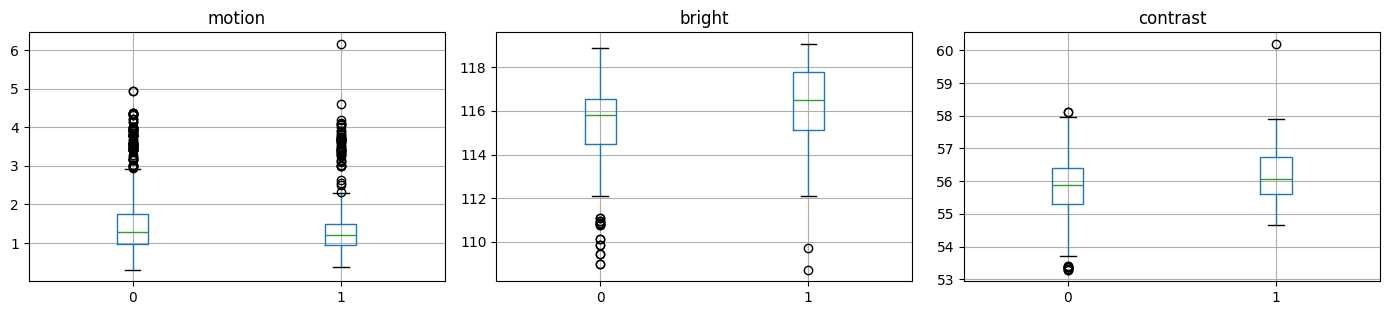

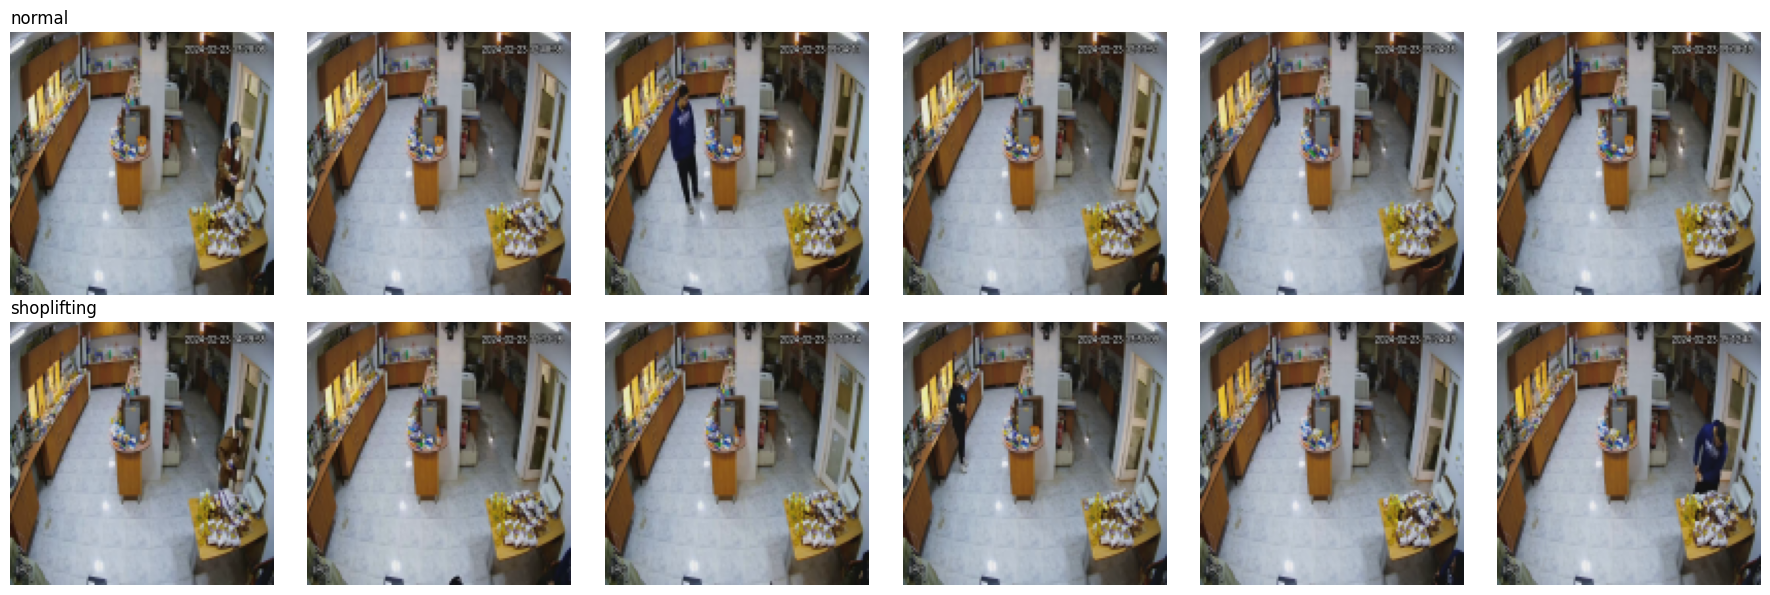

In [39]:
f32 = frames[:, :, ::4, ::4].astype(np.float32)
df["motion"] = np.abs(np.diff(f32, axis=1)).mean((1, 2, 3, 4))
df["bright"] = f32.mean((1, 2, 3, 4))
df["contrast"] = f32.std((2, 3, 4)).mean(1)

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
for a, c in zip(ax, ["motion", "bright", "contrast"]):
    df.boxplot(column=c, by="label", ax=a); a.set_title(c); a.set_xlabel("")
plt.suptitle(""); plt.tight_layout(); plt.show()

rng = np.random.RandomState(0)
fig, ax = plt.subplots(2, 6, figsize=(18, 6))
for r, l in enumerate((0, 1)):
    for c, j in enumerate(rng.choice(np.where(labels == l)[0], 6, replace=False)):
        ax[r, c].imshow(frames[j, K // 2]); ax[r, c].axis("off")
    ax[r, 0].set_title(names[l], loc="left")
plt.tight_layout(); plt.show()

In [40]:
feat = ["sec", "n", "fps", "w", "h", "motion", "bright", "contrast"]
X = df[feat].fillna(df[feat].median())
single = X.apply(lambda c: roc_auc_score(labels, c)).round(3)
base = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
p = cross_val_predict(base, X, labels, cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print(single.to_string())
print("metadata-only baseline AUC:", round(roc_auc_score(labels, p), 3))

sec         0.383
n           0.374
fps         0.396
w           0.500
h           0.500
motion      0.463
bright      0.639
contrast    0.593
metadata-only baseline AUC: 0.755


## Split

In [41]:
tr_idx, tmp = train_test_split(np.arange(len(df)), test_size=0.3, stratify=labels, random_state=SEED)
va_idx, te_idx = train_test_split(tmp, test_size=0.5, stratify=labels[tmp], random_state=SEED)
print(pd.DataFrame({k: pd.Series(labels[v]).value_counts() for k, v in
                    dict(train=tr_idx, val=va_idx, test=te_idx).items()}).rename(index=names).to_string())

             train  val  test
normal         371   80    80
shoplifting    227   48    49


## Augmentation and dataset

In [42]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def augment(x, train):
    # x: (T, 3, H, W) in [0, 1]; every random parameter is drawn once and applied to all frames
    H, W = x.shape[-2:]
    if train:
        if random.random() < 0.5:
            x = x.flip(-1)
        s = random.uniform(0.7, 1.0)
        r = math.exp(random.uniform(math.log(3 / 4), math.log(4 / 3)))
        ch = min(H, int(round(H * math.sqrt(s / r))))
        cw = min(W, int(round(W * math.sqrt(s * r))))
        top, left = random.randint(0, H - ch), random.randint(0, W - cw)
        x = x[..., top:top + ch, left:left + cw]
    x = F.interpolate(x, size=(IMG, IMG), mode="bilinear", align_corners=False)
    if train:
        b, c, sat = (random.uniform(0.8, 1.2) for _ in range(3))
        x = x * b
        x = (x - x.mean()) * c + x.mean()
        g = x.mean(1, keepdim=True)
        x = (g + (x - g) * sat).clamp(0, 1)
    return x

class ClipDS(torch.utils.data.Dataset):
    def __init__(self, idx, train):
        self.idx, self.train = np.asarray(idx), train
    def __len__(self):
        return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]
        if self.train:
            n = random.randint(int(0.6 * K), K)
            sel = random.randint(0, K - n) + sample_indices(n, T, jitter=True)
        else:
            sel = sample_indices(K, T)
        x = torch.from_numpy(frames[j][sel]).permute(0, 3, 1, 2).float().div_(255)
        x = (augment(x, self.train) - MEAN) / STD
        return x, torch.tensor(float(labels[j]))

NW = min(4, os.cpu_count() or 1)
def make_loader(idx, train):
    return torch.utils.data.DataLoader(ClipDS(idx, train), batch_size=BATCH, shuffle=train, drop_last=train,
                                       num_workers=NW, pin_memory=AMP, persistent_workers=NW > 0)
train_dl, val_dl, test_dl = make_loader(tr_idx, True), make_loader(va_idx, False), make_loader(te_idx, False)

augmentation identical across frames: ok
dataset shape (T, C, H, W): (16, 3, 112, 112)


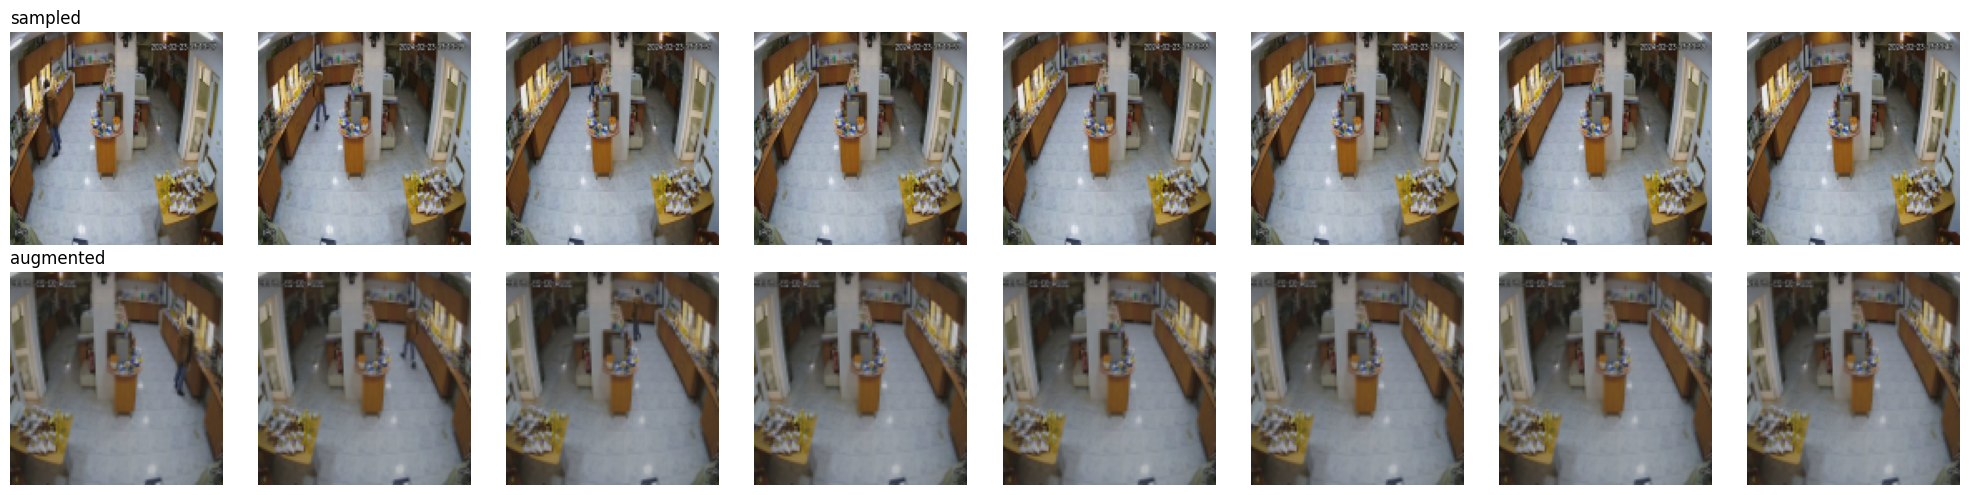

In [43]:
base_frame = torch.rand(1, 3, CACHE_SIZE, CACHE_SIZE)
for _ in range(10):
    out = augment(base_frame.repeat(T, 1, 1, 1), True)
    assert out.shape == (T, 3, IMG, IMG) and all(torch.allclose(out[0], o) for o in out)
print("augmentation identical across frames: ok")

for ds in (ClipDS(tr_idx, True), ClipDS(va_idx, False)):
    assert all(ds[i][0].shape == (T, 3, IMG, IMG) for i in range(min(8, len(ds))))
print("dataset shape (T, C, H, W):", tuple(ds[0][0].shape))

x, _ = ClipDS(tr_idx[:1], True)[0]
raw = frames[tr_idx[0]][sample_indices(K, T)]
x = (x * STD + MEAN).clamp(0, 1).permute(0, 2, 3, 1).numpy()
fig, ax = plt.subplots(2, 8, figsize=(20, 5))
for k in range(8):
    ax[0, k].imshow(raw[k * 2]); ax[1, k].imshow(x[k * 2]); ax[0, k].axis("off"); ax[1, k].axis("off")
ax[0, 0].set_title("sampled", loc="left"); ax[1, 0].set_title("augmented", loc="left")
plt.tight_layout(); plt.show()

## Model: from-scratch residual CNN (RGB + motion) with LSTM, attention pooling and appearance shortcut

In [50]:
class Block(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.c1, self.b1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False), nn.BatchNorm2d(cout)
        self.c2, self.b2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False), nn.BatchNorm2d(cout)
        self.sk = (nn.Identity() if stride == 1 and cin == cout else
                   nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout)))
    def forward(self, x):
        y = F.relu(self.b1(self.c1(x)), inplace=True)
        return F.relu(self.b2(self.c2(y)) + self.sk(x), inplace=True)

class Net(nn.Module):
    def __init__(self, d=256, h=128, drop=0.25):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(6, 32, 3, 2, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            Block(32, 64, 2), Block(64, 64, 1), Block(64, 128, 2), Block(128, 128, 1),
            Block(128, 256, 2), Block(256, 256, 1), nn.AdaptiveAvgPool2d(1), nn.Flatten())
        for m in self.enc.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")
        for m in self.enc.modules():
            if isinstance(m, Block):
                nn.init.zeros_(m.b2.weight)
        self.proj = nn.Sequential(nn.Linear(256, d), nn.LayerNorm(d), nn.GELU())
        self.gru = nn.LSTM(d, h, batch_first=True, bidirectional=True)
        self.att = nn.Linear(2 * h, 1)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(4 * h + d, 64), nn.GELU(), nn.Dropout(drop), nn.Linear(64, 1))
    def forward(self, x):
        B, T_ = x.shape[:2]
        motion = torch.cat([torch.zeros_like(x[:, :1]), x[:, 1:] - x[:, :-1]], 1)
        z = self.proj(self.enc(torch.cat([x, motion], 2).flatten(0, 1))).view(B, T_, -1)
        o, _ = self.gru(z)
        a = torch.softmax(self.att(o), 1)
        return self.head(torch.cat([(a * o).sum(1), o.amax(1), z.mean(1)], 1)).squeeze(1)

model = Net().to(device)
print(sum(p.numel() for p in model.parameters()) / 1e6, "M parameters")
with torch.no_grad():
    print(model.eval()(torch.randn(2, T, 3, IMG, IMG, device=device)).shape)

3.26989 M parameters
torch.Size([2])


## Sanity check: the model must memorize 32 clips

In [51]:
sub = np.concatenate([tr_idx[labels[tr_idx] == 0][:16], tr_idx[labels[tr_idx] == 1][:16]])
sx, sy = next(iter(torch.utils.data.DataLoader(ClipDS(sub, False), batch_size=32)))
sx, sy = sx.to(device), sy.to(device)
m = Net().to(device).train()
o = torch.optim.AdamW(m.parameters(), lr=1e-3)
for i in range(80):
    loss = F.binary_cross_entropy_with_logits(m(sx), sy)
    o.zero_grad(); loss.backward(); o.step()
    if i % 20 == 19:
        print(i + 1, round(loss.item(), 4))
del m, o, sx, sy
torch.cuda.empty_cache()

20 0.0088
40 0.0001
60 0.0
80 0.0


## Training

In [46]:
class EMA:
    def __init__(self, m, decay=0.99):
        self.m, self.d = copy.deepcopy(m).eval(), decay
        for p in self.m.parameters():
            p.requires_grad_(False)
    @torch.no_grad()
    def update(self, m):
        for e, p in zip(self.m.state_dict().values(), m.state_dict().values()):
            e.mul_(self.d).add_(p.detach(), alpha=1 - self.d) if e.dtype.is_floating_point else e.copy_(p)

@torch.no_grad()
def predict(m, dl, tta=False):
    m.eval(); ps, ys = [], []
    for x, y in dl:
        x = x.to(device, non_blocking=True)
        with torch.autocast(device.type, enabled=AMP):
            lo = m(x).float()
            if tta:
                lo = (lo + m(x.flip(-1)).float()) / 2
        ps.append(torch.sigmoid(lo).cpu()); ys.append(y)
    return torch.cat(ps).numpy(), torch.cat(ys).numpy()

def best_thr(y, p):
    t = np.linspace(0.05, 0.95, 91)
    pred = p[None] > t[:, None]
    tp, fp, fn = (pred & (y == 1)).sum(1), (pred & (y == 0)).sum(1), (~pred & (y == 1)).sum(1)
    f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    return t[f1.argmax()], f1.max()

In [52]:
model = Net().to(device)
ema = EMA(model)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
steps, warm = EPOCHS * len(train_dl), 3 * len(train_dl)
sched = torch.optim.lr_scheduler.LambdaLR(
    opt, lambda i: min(1, (i + 1) / warm) * (0.01 + 0.99 * 0.5 * (1 + math.cos(math.pi * min(i, steps) / steps))))
scaler = torch.cuda.amp.GradScaler(enabled=AMP)
ytr = labels[tr_idx]
crit = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((ytr == 0).sum() / (ytr == 1).sum(), dtype=torch.float32, device=device))

best, bad, hist = -1, 0, []
for ep in range(EPOCHS):
    model.train(); tl, ps, ys = 0, [], []
    for x, y in train_dl:
        x, y = x.to(device, non_blocking=True), y.to(device)
        with torch.autocast(device.type, enabled=AMP):
            lo = model(x).float()
        loss = crit(lo, y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 2.0)
        scaler.step(opt); scaler.update(); sched.step(); ema.update(model)
        tl += loss.item() * len(x)
        ps.append(torch.sigmoid(lo.detach()).cpu()); ys.append(y.cpu())
    pv, yv = predict(ema.m, val_dl)
    auc, (thr, f1) = roc_auc_score(yv, pv), best_thr(yv, pv)
    hist.append(dict(loss=tl / (len(train_dl) * BATCH), train_auc=roc_auc_score(torch.cat(ys), torch.cat(ps)),
                     val_auc=auc, val_f1=f1))
    print(f"ep {ep + 1:03d}  loss {hist[-1]['loss']:.4f}  train auc {hist[-1]['train_auc']:.3f}  val auc {auc:.4f}  val f1 {f1:.4f}")
    if (auc + f1) / 2 > best:
        best, bad = (auc + f1) / 2, 0
        torch.save(ema.m.state_dict(), f"{WORK}/best.pt")
    else:
        bad += 1
        if bad >= PATIENCE:
            break

ep 001  loss 0.8679  train auc 0.467  val auc 0.6406  val f1 0.5455
ep 002  loss 0.8627  train auc 0.527  val auc 0.6615  val f1 0.5781
ep 003  loss 0.8692  train auc 0.490  val auc 0.6806  val f1 0.5455
ep 004  loss 0.8609  train auc 0.502  val auc 0.7219  val f1 0.5455
ep 005  loss 0.8642  train auc 0.540  val auc 0.7827  val f1 0.5455
ep 006  loss 0.8580  train auc 0.550  val auc 0.7669  val f1 0.5455
ep 007  loss 0.8683  train auc 0.482  val auc 0.7750  val f1 0.5455
ep 008  loss 0.8613  train auc 0.498  val auc 0.8029  val f1 0.5455
ep 009  loss 0.8518  train auc 0.605  val auc 0.8086  val f1 0.6429
ep 010  loss 0.8515  train auc 0.576  val auc 0.8229  val f1 0.6667
ep 011  loss 0.8293  train auc 0.629  val auc 0.8216  val f1 0.7544
ep 012  loss 0.8092  train auc 0.675  val auc 0.8190  val f1 0.7478
ep 013  loss 0.7725  train auc 0.712  val auc 0.8255  val f1 0.7544
ep 014  loss 0.7656  train auc 0.722  val auc 0.8365  val f1 0.7748
ep 015  loss 0.7066  train auc 0.775  val auc 0.

## Evaluation

                           accuracy  precision  recall      f1     auc
threshold 0.5                0.9767     0.9600  0.9796  0.9697  0.9972
threshold 0.74 (from val)    0.9767     0.9792  0.9592  0.9691  0.9972


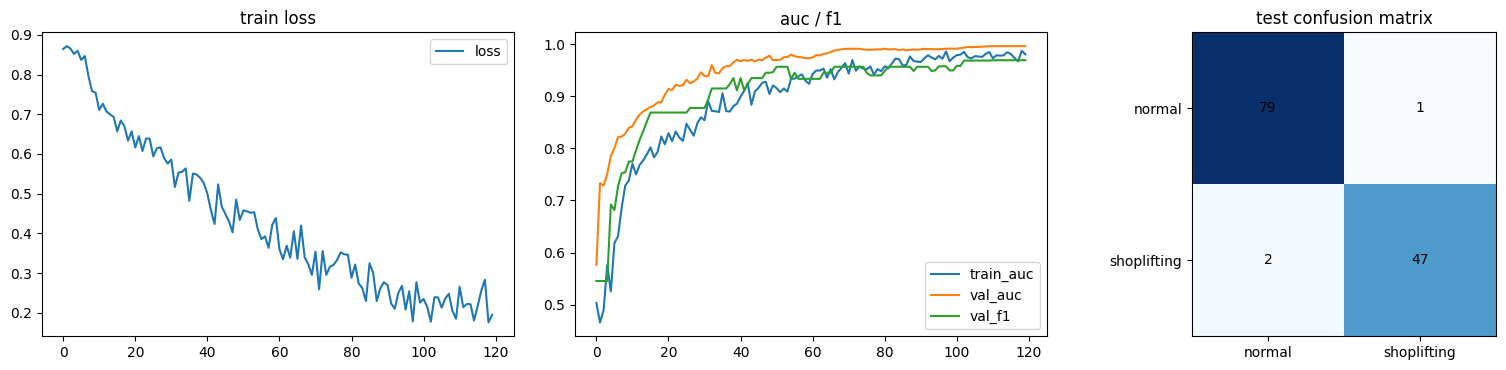

In [48]:
final = Net().to(device)
final.load_state_dict(torch.load(f"{WORK}/best.pt", map_location=device))
pv, yv = predict(final, val_dl, tta=True)
thr, _ = best_thr(yv, pv)
pt, yt = predict(final, test_dl, tta=True)

rows = {}
for name, t in (("threshold 0.5", 0.5), (f"threshold {thr:.2f} (from val)", thr)):
    pred = (pt > t).astype(int)
    rows[name] = dict(accuracy=accuracy_score(yt, pred), precision=precision_score(yt, pred),
                      recall=recall_score(yt, pred), f1=f1_score(yt, pred), auc=roc_auc_score(yt, pt))
print(pd.DataFrame(rows).T.round(4).to_string())

h = pd.DataFrame(hist)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
h[["loss"]].plot(ax=ax[0], title="train loss")
h[["train_auc", "val_auc", "val_f1"]].plot(ax=ax[1], title="auc / f1")
cm = confusion_matrix(yt, (pt > thr).astype(int))
ax[2].imshow(cm, cmap="Blues"); ax[2].set_title("test confusion matrix")
ax[2].set_xticks([0, 1], ["normal", "shoplifting"]); ax[2].set_yticks([0, 1], ["normal", "shoplifting"])
for (i, j), v in np.ndenumerate(cm):
    ax[2].text(j, i, v, ha="center", va="center", color="black")
plt.tight_layout(); plt.show()